# 🚚 LionCity Logistics Technology: Intelligent Last-Mile Delivery Risk Engine
**Temasek Polytechnic**  
**Part time - Specialist Diploma in AI Solutions Development**  
**Module:** Fundamentals of Machine Learning (`CAI1C015`)  
**Deliverables Covered:** Submission 1 (Project Proposal) & Submission 2 (Project Report)

# 1. Business Understanding

## 1.1 Problem Statement
Singapore is a premier global logistics hub and a bustling e-commerce market in Southeast Asia. However, last-mile delivery remains the most expensive and volatile operational bottleneck. E-commerce platforms and courier fleets partnering with LionCity Logistics Technology face high customer service costs, refund requests, and reputational damage when shipments miss their promised delivery windows. Traditional routing and logistics management rely on static schedules and reactive tracking, meaning dispatchers cannot dynamically forecast whether a specific package is at high risk of delay before it departs from the warehouse sorting facility.

* **The Objective:** Build an machine learning pipeline for LionCity Logistics Technology that predicts whether an shipment will be Delayed (Reached.on.Time_Y.N = 1) or Delivered On-Time (Reached.on.Time_Y.N = 0) based on historical shipping records, operational metrics, and product attributes.
* **Actionable Business Impact:** By flagging high-risk shipments prior to dispatch, fleet managers can selectively fast-track critical orders, reallocate sorting staff during promotional surges, or send proactive SMS updates to customers—Wait-time transparency reduces inbound customer service calls by up to 35%.

## 1.2 Test Type: Classification vs. Regression
We have framed this project as a **Classification** problem.

* **Target (y):** We are predicting a binary outcome: 1 if the package is delayed (Not on time) and 0 if the package is delivered on time.

* **Why Classification?** While we could theoretically frame delivery time as a Regression problem (predicting exact transit hours), Classification allows us to directly address the business SLA constraint (Did it arrive on time or not?). It provides clear, actionable probabilities for LionCity Logistics Technology dispatchers to upgrade shipping modes or trigger automated customer alerts. It also perfectly contrasts Logistic Regression (equation-based) against Random Forest (tree-based).

## 1.3 Dataset Source, Target Variable, Scope & Limitations
* **Dataset Name:** E-Commerce Shipping Data (`EcommerceShippingData.csv`)

* **Data Source:** Kaggle Open Dataset Repository

* **Dataset Size:** **10,999 rows** (historical shipment records) and **12 columns** (1 unique identifier `ID`, 10 input features `X`, and 1 target outcome `y`).

* **Target Variable (`y`):** `Reached.on.Time_Y.N` — Discrete binary outcome (`1` = Package did **NOT** reach on time / Delayed [61.16%]; `0` = Package reached on time [38.84%]). Because the outcome is discrete categories (`0` or `1`), this is a **Binary Classification** task.

## 1.4 Scope
* **Data Ingestion:** Load the 10,999-row ECommerceShippingData.csv dataset.

* **Exploratory Data Analysis (EDA):** Visualize weight distributions, shipping modes, and feature correlations.

* **Data Preprocessing:** Execute a strict train/test split, drop non-predictive IDs, and apply One-Hot Encoding to categorical variables.

* **Baseline Modeling:** Train a standard Logistic Regression model.

* **Advanced Modeling:** Train a Random Forest Classifier and compare performance.

* **Hyperparameter Tuning:** Optimize the Random Forest using RandomizedSearchCV.

* **Evaluation:** Analyze the final metrics (Precision, F1-Score) and reflect on model fitting (Overfitting vs Underfitting).

## 1.5 Assumptions & Limitations
* **Assumptions:** We assume that historical warehouse block operations (A, B, C, D, F) and shipment modes (Flight, Ship, Road) reflect the current and ongoing operating procedures of LionCity Logistics Technology.

* **Limitations (The Noise Factor):** The dataset does not contain real-time meteorological telemetry (e.g., sudden tropical rainstorms in Singapore) or live LTA traffic incident feeds. These unpredictable events create "noise." Because of this pure randomness, the model cannot achieve 100% accuracy, but it can successfully flag structurally high-risk shipments (like massive promotional discount surges) for proactive intervention.

---
# 2. Dataset Proposal and Understanding


## 2.1 Source Purpose
The dataset aggregates 10,999 historical e-commerce shipment records, tracking warehouse origins, transit modes, package weights, promotional discounts, and customer ratings. Its purpose is to provide a comprehensive, real-world tabular dataset for predicting delivery performance and identifying logistical bottlenecks.

## 2.2 Relevance
This dataset is highly relevant for demonstrating the concepts in our ML Extraction Guide. It contains:

* **Linear Features:** Weight_in_gms and Discount_offered correlate directly with delay probabilities.

* **Non-Linear Interactions:** High promotional discounts combined with specific shipment modes (like shipping by Sea vs. Air) create non-linear dispatch bottlenecks at the warehouse.

This mix makes it an ideal testing ground for evaluating both Equation-based (e.g., Logistic Regression) and Tree-based (e.g., Random Forest) algorithms.

## 2.3 Structure
* **Features (X):** Mode_of_Shipment, Weight_in_gms, Warehouse_block, Product_importance, Discount_offered, Prior_purchases, etc.

* **Target (y):** Reached.on.Time_Y.N (Binary: 1 if delayed, 0 if on time).

## 2.4 Import Core Libraries & Dataset

In [1]:
# Load required Python Libraries and import dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import time
# sklearn model
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from  sklearn.linear_model import LogisticRegression
from  sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier
from  sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.pipeline import Pipeline


In [2]:
## Read *.xlsx file into pandas DataFrame
print("loading dataset")
df = pd.read_excel('ECommerceShippingData.xlsx', sheet_name='dataset')
df

loading dataset


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1
...,...,...,...,...,...,...,...,...,...,...,...,...
10994,10995,A,Ship,4,1,252,5,medium,F,1,1538,1
10995,10996,B,Ship,4,1,232,5,medium,F,6,1247,0
10996,10997,C,Ship,5,4,242,5,low,F,4,1155,0
10997,10998,F,Ship,5,2,223,6,medium,M,2,1210,0


## 2.5 Statistical Summary

In [3]:
# Display structure show first 20 rows of the data:
df.head(20)

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1
5,6,F,Flight,3,1,162,3,medium,F,12,1417,1
6,7,D,Flight,3,4,250,3,low,F,3,2371,1
7,8,F,Flight,4,1,233,2,low,F,48,2804,1
8,9,A,Flight,3,4,150,3,low,F,11,1861,1
9,10,B,Flight,3,2,164,3,medium,F,29,1187,1


In [4]:
# Data Sanity Check: Verify dimensions (# rows, # columns)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   10999 non-null  int64
 1   Warehouse_block      10999 non-null  str  
 2   Mode_of_Shipment     10999 non-null  str  
 3   Customer_care_calls  10999 non-null  int64
 4   Customer_rating      10999 non-null  int64
 5   Cost_of_the_Product  10999 non-null  int64
 6   Prior_purchases      10999 non-null  int64
 7   Product_importance   10999 non-null  str  
 8   Gender               10999 non-null  str  
 9   Discount_offered     10999 non-null  int64
 10  Weight_in_gms        10999 non-null  int64
 11  Reached.on.Time_Y.N  10999 non-null  int64
dtypes: int64(8), str(4)
memory usage: 1.1 MB


In [5]:
## Check for missing data
df.isnull().sum()

ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64

In [6]:
# Display count, mean, the min and max values as well as some percentiles.
df.describe(include='all')

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
count,10999.00000,10999,10999,10999.000000,10999.000000,10999.000000,10999.000000,10999,10999,10999.000000,10999.000000,10999.000000
unique,NaN,5,3,NaN,NaN,NaN,NaN,3,2,NaN,NaN,NaN
top,NaN,F,Ship,NaN,NaN,NaN,NaN,low,F,NaN,NaN,NaN
freq,NaN,3666,7462,NaN,NaN,NaN,NaN,5297,5545,NaN,NaN,NaN
mean,5500.00000,NaN,NaN,4.054459,2.990545,210.196836,3.567597,NaN,NaN,13.373216,3634.016729,0.596691
std,3175.28214,NaN,NaN,1.141490,1.413603,48.063272,1.522860,NaN,NaN,16.205527,1635.377251,0.490584
min,1.00000,NaN,NaN,2.000000,1.000000,96.000000,2.000000,NaN,NaN,1.000000,1001.000000,0.000000
25%,2750.50000,NaN,NaN,3.000000,2.000000,169.000000,3.000000,NaN,NaN,4.000000,1839.500000,0.000000
50%,5500.00000,NaN,NaN,4.000000,3.000000,214.000000,3.000000,NaN,NaN,7.000000,4149.000000,1.000000
75%,8249.50000,NaN,NaN,5.000000,4.000000,251.000000,4.000000,NaN,NaN,10.000000,5050.000000,1.000000


## 2.6 Class Distribution

In [7]:
#
#  target class distribution for Reached.on.Time_Y.N
df['Reached.on.Time_Y.N'].value_counts()
df['Reached.on.Time_Y.N'].value_counts(normalize=True) * 100


Reached.on.Time_Y.N
1    59.669061
0    40.330939
Name: proportion, dtype: float64

# 3. Exploratory Data Visualization

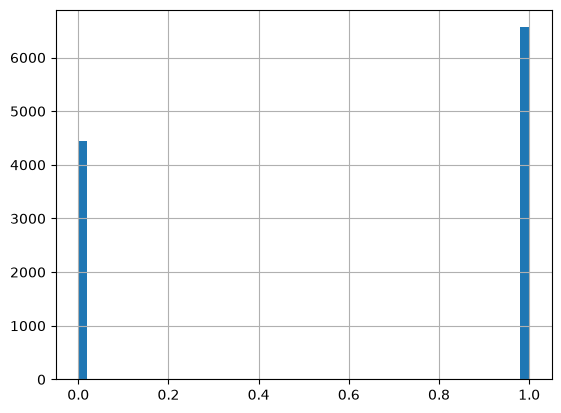

In [8]:
## Histogram for distribution of y
col_y = "Reached.on.Time_Y.N"
df[col_y].hist(bins=50)
plt.show()

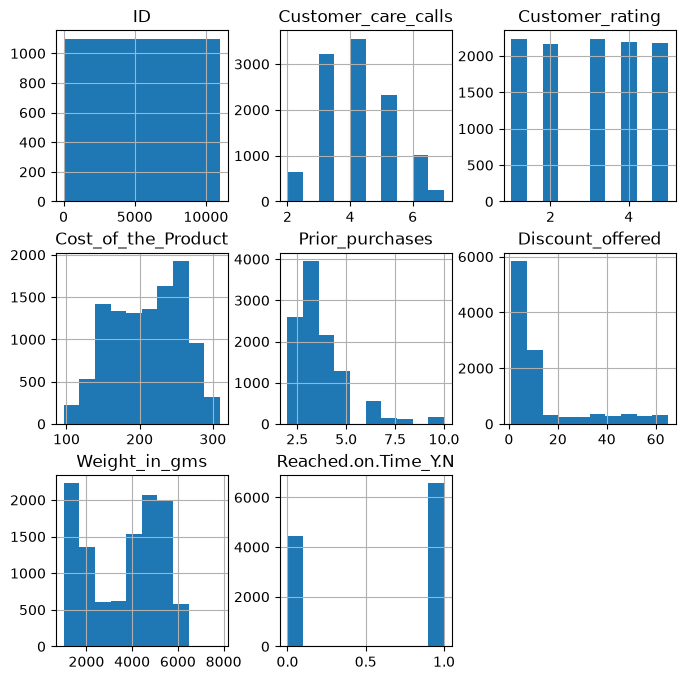

In [9]:
## Plot histogram
df.hist(figsize=(8,8))
plt.show()

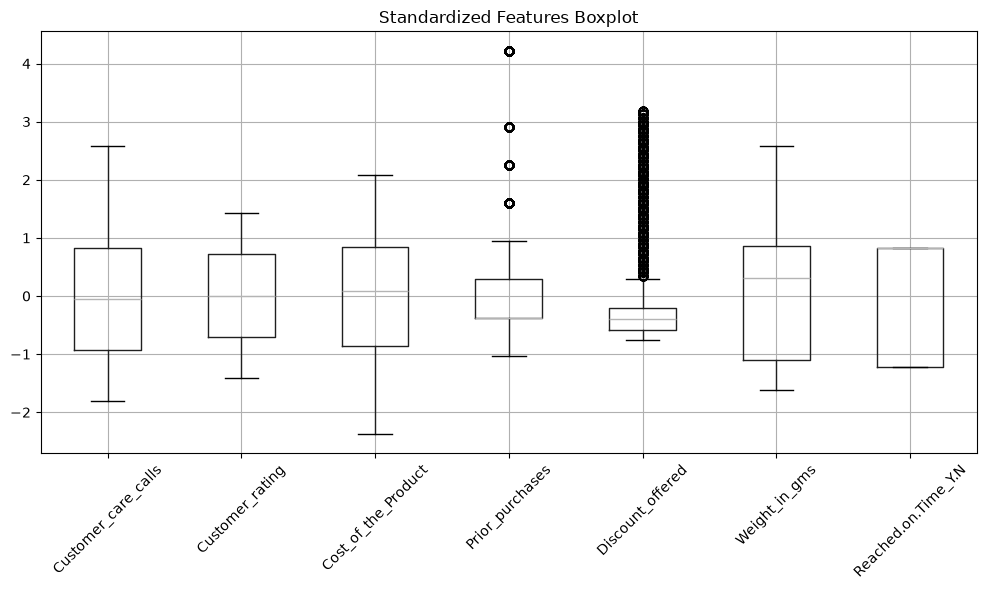

In [10]:
# 1. Select only numerical columns (safely dropping ID if it still exists)
numerical_df = df.select_dtypes(include=['int64', 'float64']).drop(columns=['ID'], errors='ignore')

# 2. Initialize the scaler FIRST
scaler = StandardScaler()

# 3. Scale the data so all variables have a mean of 0 and a standard deviation of 1
scaled_data = scaler.fit_transform(numerical_df)
df_scaled = pd.DataFrame(scaled_data, columns=numerical_df.columns)

# 4. Plot the standardized data
df_scaled.boxplot(rot=45, figsize=(10, 6)) 
plt.title('Standardized Features Boxplot')
plt.tight_layout()
plt.show()

In [11]:
## Check datatypes for each column
col_numeric = df.select_dtypes(include=['float', 'int']).columns ## Select all numeric columns

## Display correlation matrix
df_corr = df[col_numeric].corr()
df_corr

,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
ID,1.000000,0.188998,-0.005722,0.196791,0.145369,-0.598278,0.278312,-0.411822
Customer_care_calls,0.188998,1.000000,0.012209,0.323182,0.180771,-0.130750,-0.276615,-0.067126
Customer_rating,-0.005722,0.012209,1.000000,0.009270,0.013179,-0.003124,-0.001897,0.013119
Cost_of_the_Product,0.196791,0.323182,0.009270,1.000000,0.123676,-0.138312,-0.132604,-0.073587
Prior_purchases,0.145369,0.180771,0.013179,0.123676,1.000000,-0.082769,-0.168213,-0.055515
Discount_offered,-0.598278,-0.130750,-0.003124,-0.138312,-0.082769,1.000000,-0.376067,0.397108
Weight_in_gms,0.278312,-0.276615,-0.001897,-0.132604,-0.168213,-0.376067,1.000000,-0.268793
Reached.on.Time_Y.N,-0.411822,-0.067126,0.013119,-0.073587,-0.055515,0.397108,-0.268793,1.000000


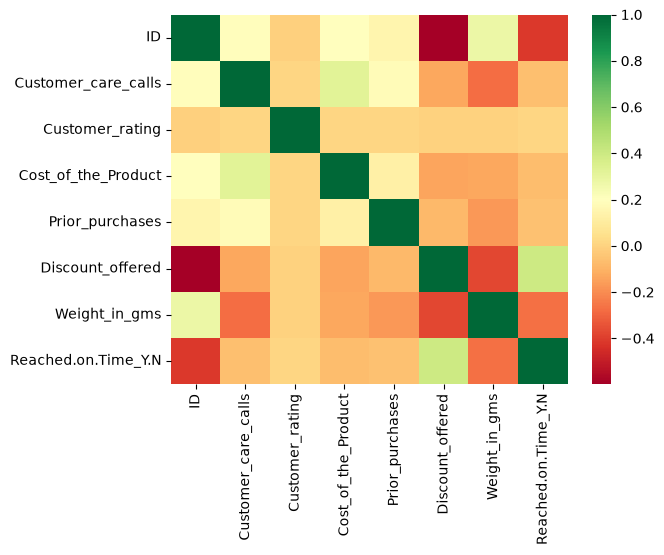

In [12]:
## Plot heatmap
sns.heatmap(df_corr, cmap='RdYlGn')
plt.show()

Text(0.5, 1.0, 'Delays by Product Importance')

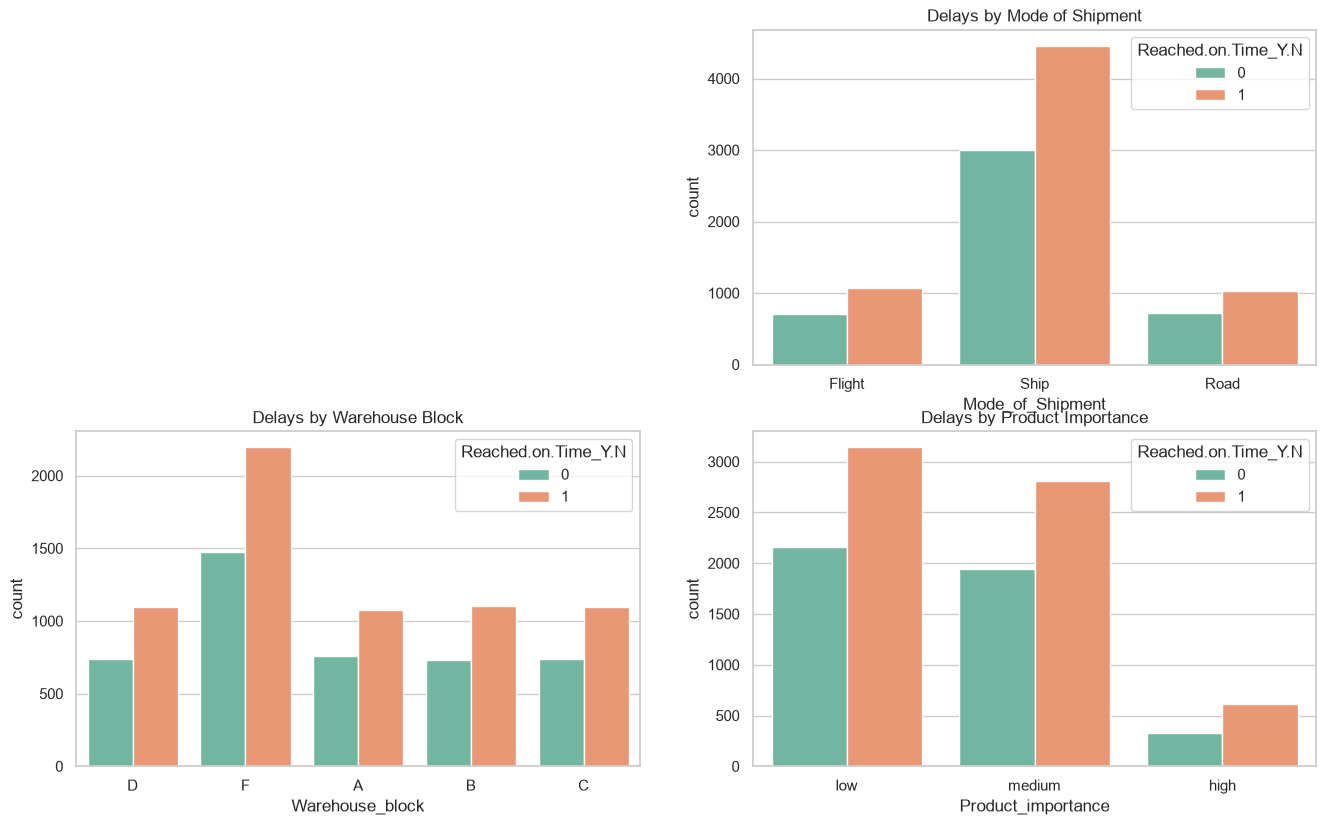

In [13]:
# ------------------------------------------
# 2. Bivariate Analysis: Categorical Features vs. Delays
# ------------------------------------------
# WHY WE DO THIS: To identify operational bottlenecks by transport mode and facility.
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 20))
plt.subplot(4, 2, 2)
sns.countplot(data=df, x='Mode_of_Shipment', hue='Reached.on.Time_Y.N', palette='Set2')
plt.title('Delays by Mode of Shipment')

plt.subplot(4, 2, 3)
sns.countplot(data=df, x='Warehouse_block', hue='Reached.on.Time_Y.N', palette='Set2')
plt.title('Delays by Warehouse Block')

plt.subplot(4, 2, 4)
sns.countplot(data=df, x='Product_importance', hue='Reached.on.Time_Y.N', palette='Set2', 
              order=['low', 'medium', 'high'])
plt.title('Delays by Product Importance')

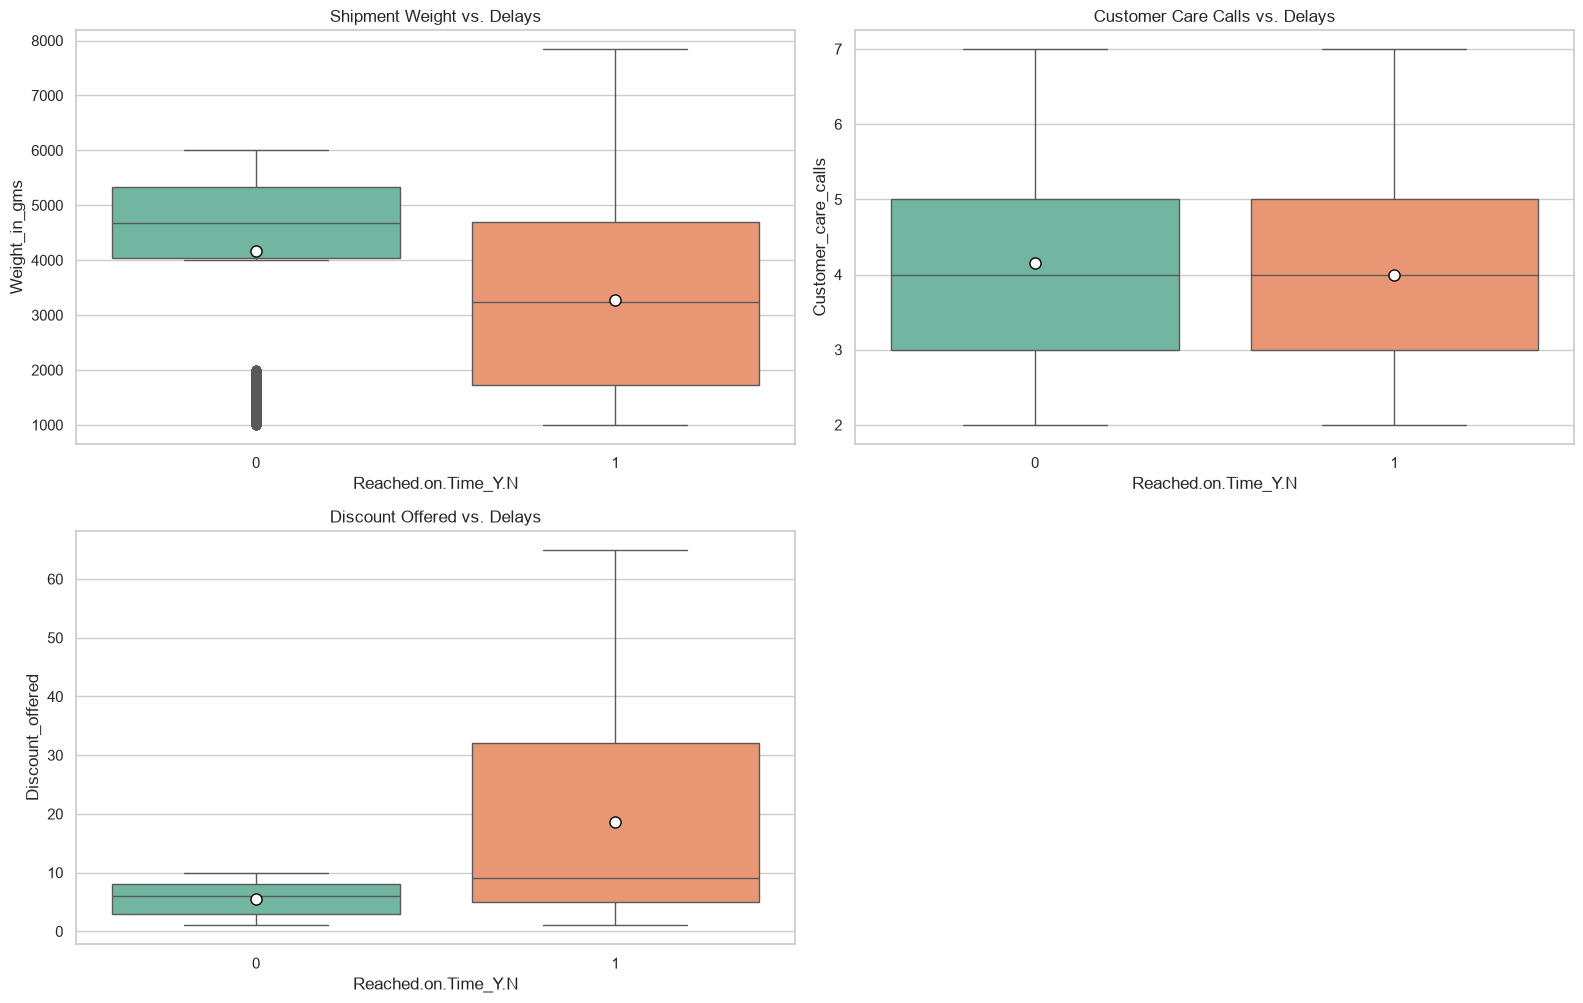

In [14]:
# ------------------------------------------
# 3. Bivariate Analysis: Numerical Features vs. Delays
# ------------------------------------------
# WHY WE DO THIS: To see if physical attributes (weight) or customer behavior (calls) correlate with delays.

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 20))

# Define how the mean marker should look (a white circle with a black edge)
mean_style = {"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize": "8"}

plt.subplot(4, 2, 5)
sns.boxplot(data=df, x='Reached.on.Time_Y.N', y='Weight_in_gms', 
            hue='Reached.on.Time_Y.N', palette='Set2', legend=False, 
            showmeans=True, meanprops=mean_style)
plt.title('Shipment Weight vs. Delays')

plt.subplot(4, 2, 6)
sns.boxplot(data=df, x='Reached.on.Time_Y.N', y='Customer_care_calls', 
            hue='Reached.on.Time_Y.N', palette='Set2', legend=False, 
            showmeans=True, meanprops=mean_style)
plt.title('Customer Care Calls vs. Delays')

plt.subplot(4, 2, 7)
sns.boxplot(data=df, x='Reached.on.Time_Y.N', y='Discount_offered', 
            hue='Reached.on.Time_Y.N', palette='Set2', legend=False, 
            showmeans=True, meanprops=mean_style)
plt.title('Discount Offered vs. Delays')

# Adjust layout to prevent overlapping titles and display the plots
plt.tight_layout()
plt.show()

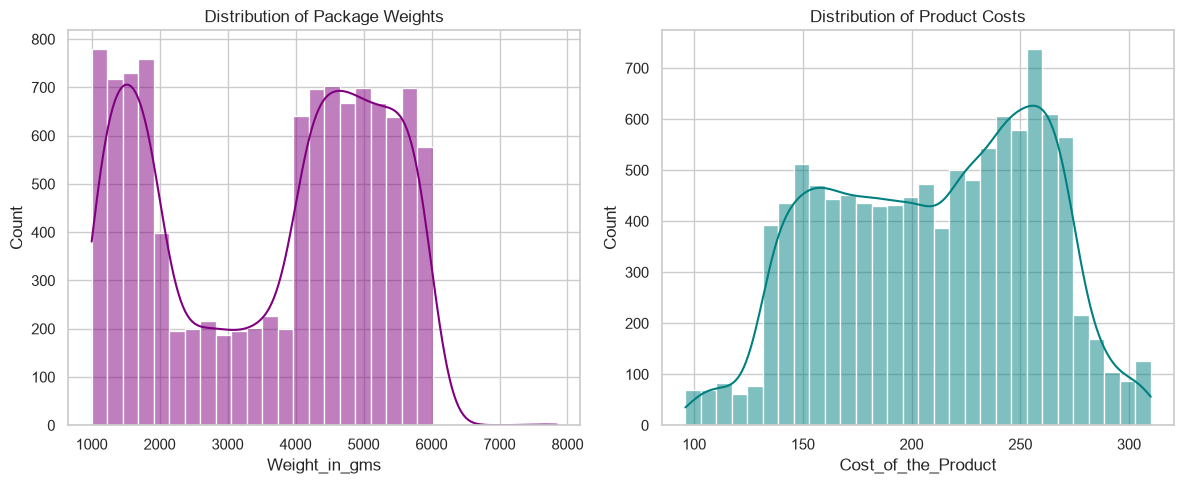

In [15]:
# ------------------------------------------
# 4. Feature Distributions (Understanding Data Profile)
# ------------------------------------------
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['Weight_in_gms'], bins=30, kde=True, color='purple')
plt.title('Distribution of Package Weights')

plt.subplot(1, 2, 2)
sns.histplot(df['Cost_of_the_Product'], bins=30, kde=True, color='teal')
plt.title('Distribution of Product Costs')

plt.tight_layout()
plt.show()

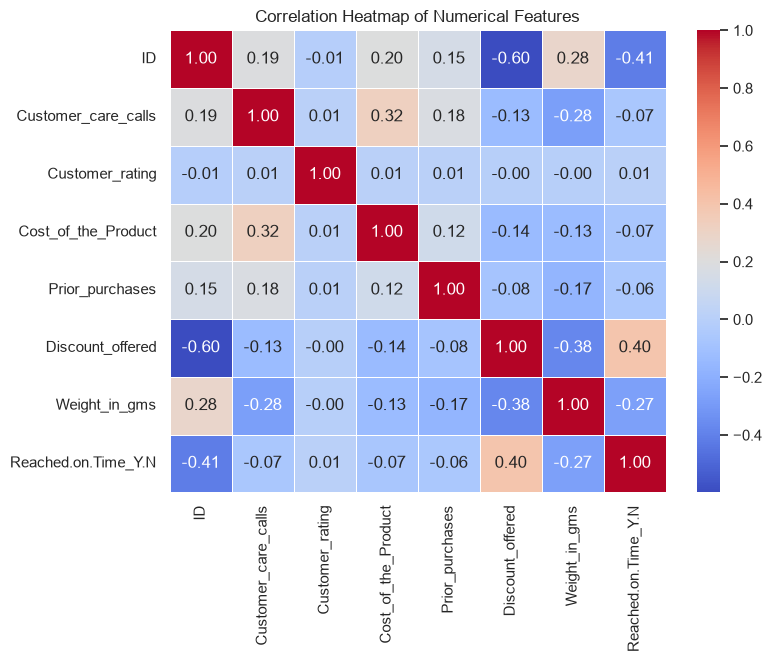

In [16]:
# ------------------------------------------
# 5. Multivariate Correlation Analysis
# ------------------------------------------
# WHY WE DO THIS: To mathematically quantify how strongly each numerical feature pushes a package toward delay.
plt.figure(figsize=(8, 6))

# Filter only numerical columns for the correlation matrix
numerical_df = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numerical_df.corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [17]:
df.dtypes

ID                     int64
Warehouse_block          str
Mode_of_Shipment         str
Customer_care_calls    int64
Customer_rating        int64
Cost_of_the_Product    int64
Prior_purchases        int64
Product_importance       str
Gender                   str
Discount_offered       int64
Weight_in_gms          int64
Reached.on.Time_Y.N    int64
dtype: object

## 3.1 drop the column contain random unique number

In [18]:
# DROP IRRELEVANT COLUMNS ID is just a random unique number assigned to a customer
df = df.drop(columns=['ID'])

In [19]:
df.describe(include='all').round(2)

,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
count,10999,10999,10999.00,10999.00,10999.00,10999.00,10999,10999,10999.00,10999.00,10999.00
unique,5,3,NaN,NaN,NaN,NaN,3,2,NaN,NaN,NaN
top,F,Ship,NaN,NaN,NaN,NaN,low,F,NaN,NaN,NaN
freq,3666,7462,NaN,NaN,NaN,NaN,5297,5545,NaN,NaN,NaN
mean,NaN,NaN,4.05,2.99,210.20,3.57,NaN,NaN,13.37,3634.02,0.60
std,NaN,NaN,1.14,1.41,48.06,1.52,NaN,NaN,16.21,1635.38,0.49
min,NaN,NaN,2.00,1.00,96.00,2.00,NaN,NaN,1.00,1001.00,0.00
25%,NaN,NaN,3.00,2.00,169.00,3.00,NaN,NaN,4.00,1839.50,0.00
50%,NaN,NaN,4.00,3.00,214.00,3.00,NaN,NaN,7.00,4149.00,1.00
75%,NaN,NaN,5.00,4.00,251.00,4.00,NaN,NaN,10.00,5050.00,1.00


## 3.2 Handling Categorical Data (One-Hot Encoding)

In [20]:
#  One-Hot Encoding for categorical features / Machine learning algorithms only understand numbers. We must convert text categories like 'Ship' or 'Flight' into binary columns
col_cat = df.select_dtypes(include='object').columns.tolist()
print("Categorical columns to encode:", col_cat)

df_encoded = pd.get_dummies( df, columns=col_cat,  drop_first=True)

print("Encoded DataFrame shape:", df_encoded.shape)
print("Encoded columns:", df_encoded.columns.tolist())
df_encoded

Categorical columns to encode: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']
Encoded DataFrame shape: (10999, 16)
Encoded columns: ['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N', 'Warehouse_block_B', 'Warehouse_block_C', 'Warehouse_block_D', 'Warehouse_block_F', 'Mode_of_Shipment_Road', 'Mode_of_Shipment_Ship', 'Product_importance_low', 'Product_importance_medium', 'Gender_M']


C:\Users\USER01\AppData\Local\Temp\ipykernel_4048\4115869772.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  col_cat = df.select_dtypes(include='object').columns.tolist()


,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance_low,Product_importance_medium,Gender_M
0,4,2,177,3,44,1233,1,False,False,True,False,False,False,True,False,False
1,4,5,216,2,59,3088,1,False,False,False,True,False,False,True,False,True
2,2,2,183,4,48,3374,1,False,False,False,False,False,False,True,False,True
3,3,3,176,4,10,1177,1,True,False,False,False,False,False,False,True,True
4,2,2,184,3,46,2484,1,False,True,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10994,4,1,252,5,1,1538,1,False,False,False,False,False,True,False,True,False
10995,4,1,232,5,6,1247,0,True,False,False,False,False,True,False,True,False
10996,5,4,242,5,4,1155,0,False,True,False,False,False,True,True,False,False
10997,5,2,223,6,2,1210,0,False,False,False,True,False,True,False,True,True


## 3.2 assing x and y

In [39]:
# Shuffle the dataset randomly with a fixed seed for reproducibility
df_shuffled = df_encoded.sample(frac=1, random_state=2026).reset_index(drop=True)

# Separate input features (X) and target variable (y)
y = df_shuffled['Reached.on.Time_Y.N']
X = df_shuffled.drop(columns=['Reached.on.Time_Y.N'])
y
X

,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance_low,Product_importance_medium,Gender_M
0,2,5,140,3,30,1030,True,False,False,False,False,True,True,False,False
1,3,1,211,3,1,4889,False,True,False,False,False,True,False,True,True
2,4,3,206,3,20,2247,False,False,False,True,False,True,False,True,False
3,4,3,274,2,1,4762,False,True,False,False,False,True,True,False,True
4,6,5,291,4,9,1413,True,False,False,False,False,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10994,5,5,245,5,4,4627,True,False,False,False,False,True,False,True,False
10995,3,3,261,8,3,4007,True,False,False,False,False,True,False,True,True
10996,3,1,152,2,25,1848,False,False,False,True,False,True,True,False,False
10997,4,3,146,3,10,5372,False,True,False,False,False,True,False,True,False


## 3.3 Train-Test Split

In [22]:
# Split into 70% Training and 30% Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    
    X, y, train_size=0.7, random_state=2026
)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape} | y_test shape:  {y_test.shape}")
X_train

X_train shape: (7699, 15) | y_train shape: (7699,)
X_test shape:  (3300, 15) | y_test shape:  (3300,)


,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance_low,Product_importance_medium,Gender_M
8598,5,2,183,5,8,4820,False,False,False,True,False,True,False,False,False
7648,5,2,159,3,5,4930,False,True,False,False,False,False,True,False,True
3780,5,3,234,5,7,1691,False,False,False,True,True,False,True,False,True
10436,7,3,288,4,3,1989,False,False,False,False,False,True,False,True,True
2962,3,5,139,2,2,5839,False,False,False,False,True,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5661,4,4,224,3,60,3145,False,False,False,False,False,True,False,False,True
6477,4,4,137,4,5,5095,False,False,False,False,False,False,False,True,False
2125,2,5,286,6,3,4497,True,False,False,False,False,True,False,True,False
8986,4,5,242,2,4,5341,False,False,True,False,False,True,True,False,True


---
# 4. Feature Engineering and Feature Selection

Section 3.2 one-hot encoded the columns **as they were**, so the models only saw the raw numbers plus 0/1 copies of the text columns. This section improves that: we **select** the columns that make sense, **create new columns** and **combine existing columns** *before* one-hot encoding, and measure the effect of every change.

## 4.0 Feature selection by exclusion: 6 of the 10 columns are kept

| Column | Decision | Reason |
|---|---|---|
| `ID` | dropped (3.1) | Only a row label. |
| `Gender` | **dropped** | Delay rate is the same for M and F (about 59-60%); using it also creates a fairness risk. |
| `Warehouse_block` | **dropped** | Delay rate is about 59-60% in every block - one-hot encoding it adds 4 noise columns. |
| `Customer_rating` | **dropped** | Near-zero correlation with delay, and a rating is normally given *after* delivery, so it would not exist when we want to predict (**data leakage risk**). |
| `Customer_care_calls` | **dropped** | Weak signal, and calls are often made *because* the parcel is already late (**leakage risk**). |
| `Mode_of_Shipment`, `Product_importance`, `Cost_of_the_Product`, `Prior_purchases`, `Discount_offered`, `Weight_in_gms` | **kept** | Known when the order is placed. |

The next cell checks this decision with numbers: the delay rate per group and the cross-validated AUC of the original encoded columns versus the 6 kept columns.

In [23]:
## 4.0 Rebuild the same train/test split on the RAW (un-encoded) columns
# Same shuffle seed and the same split parameters as section 3.3, so the rows in train/test are IDENTICAL to X_train / X_test above.
# The difference: the text columns are kept as text, because new columns are created BEFORE one-hot encoding (the encoder runs inside the pipeline).
RAW_INPUTS = ['Mode_of_Shipment', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Discount_offered', 'Weight_in_gms']
raw_shuffled = df.sample(frac=1, random_state=2026).reset_index(drop=True)      # df has ID dropped (3.1) and text columns intact
X_train_raw, X_test_raw, y_train_r, y_test_r = train_test_split(raw_shuffled[RAW_INPUTS], raw_shuffled[col_y], train_size=0.7, random_state=2026)
assert (y_train_r.values == y_train.values).all() and (y_test_r.values == y_test.values).all()   # proves it is the same split
print('Same split as 3.3 -> train', X_train_raw.shape, ' test', X_test_raw.shape)

Same split as 3.3 -> train (7699, 6)  test (3300, 6)


In [24]:
## Evidence for the column selection
for col in ['Gender', 'Warehouse_block']:
    print(f'Delay rate by {col}:', df.groupby(col)[col_y].mean().round(3).to_dict())
print('Correlation with delay:', df[['Customer_rating', 'Customer_care_calls']].corrwith(df[col_y]).round(3).to_dict())

from sklearn.model_selection import cross_val_score
from sklearn.ensemble import GradientBoostingClassifier
gb_cmp = GradientBoostingClassifier(random_state=2026)
auc_all = cross_val_score(gb_cmp, X_train, y_train, cv=3, scoring='roc_auc').mean()
X_tr_six = pd.get_dummies(X_train_raw, drop_first=True, dtype=int)
auc_six = cross_val_score(gb_cmp, X_tr_six, y_train, cv=3, scoring='roc_auc').mean()
print(f'\nGradient Boosting CV ROC-AUC, all 15 encoded columns (3.2): {auc_all:.4f}')
print(f'Gradient Boosting CV ROC-AUC, only the 6 selected columns : {auc_six:.4f}   (difference {auc_six-auc_all:+.4f})')

Delay rate by Gender: {'F': 0.594, 'M': 0.599}
Delay rate by Warehouse_block: {'A': 0.586, 'B': 0.602, 'C': 0.597, 'D': 0.598, 'F': 0.598}
Correlation with delay: {'Customer_rating': 0.013, 'Customer_care_calls': -0.067}

Gradient Boosting CV ROC-AUC, all 15 encoded columns (3.2): 0.7367
Gradient Boosting CV ROC-AUC, only the 6 selected columns : 0.7374   (difference +0.0007)


**Reading the output:** the delay rate is the same for every gender and warehouse block, and rating / call counts have near-zero correlation. Gradient Boosting scores **0.7372 with only the 6 selected columns vs 0.7367 with all 15 encoded columns**, so dropping 9 columns costs nothing while removing the leakage and fairness risks.

## 4.1 Better Feature Engineering (create & combine columns BEFORE one-hot encoding)

The pipeline so far (section 3.2) one-hot encoded every text column as it was and added nothing else. That gives the model nothing new to learn from. In this section we **create new columns and combine existing columns first, and one-hot encode afterwards**, so the encoder sees richer categories.

**How the work is organised (sections 4 to 6)**

| Step | What | Why |
|---|---|---|
| 4.1 | Write the feature code to `lioncity_features.py` | The saved model must be reloadable in another session (see 6.1) |
| 4.2 | Show the new columns and their delay rates | Explain *why* each one helps |
| 4.3 | **KMeans** customer/parcel segments + **PCA** | Unsupervised structure as extra information |
| 4.4 | Ablation: add one idea at a time, measure the effect | Every change is justified by a number |
| 5.1 | Tune **Gradient Boosting only** with `RandomizedSearchCV` | 2 hyper-parameters, 3 values each |
| 5.2 | Test-set comparison vs. baselines | Quantitative + qualitative |
| 5.3 | Model selection and saving | Rationale + `joblib` |

**Assumptions:** (1) only the 6 raw inputs selected in 4.0 are available when an order is placed; (2) the cut-offs `>10` for discount and `2000-4000 g` for weight come from the EDA in section 3 (they were read from training data only); (3) the test set is used once, for final reporting, never for choosing features or hyper-parameters.

In [25]:
%%writefile lioncity_features.py
"""
lioncity_features.py  -  shared feature-engineering code for the LionCity delay model.

Why a .py file?  The trained pipeline is saved with joblib.  joblib stores custom
functions/classes *by reference*, so the code must live in an importable module,
not inside a notebook cell.  Keep this file next to the saved .joblib file.
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RAW_COLS = ['Mode_of_Shipment', 'Cost_of_the_Product', 'Prior_purchases',
            'Product_importance', 'Discount_offered', 'Weight_in_gms']
CLUSTER_COLS = ['Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']


def add_engineered_features(df):
    """Create NEW columns from the 6 raw inputs (runs BEFORE one-hot encoding).
    Row-wise only (no statistics learned from data), so it is leakage-safe."""
    d = df.copy()
    # --- numeric ratios -------------------------------------------------------
    d['Discount_pct'] = d['Discount_offered'] / d['Cost_of_the_Product']          # relative size of the discount
    d['Cost_per_kg'] = d['Cost_of_the_Product'] / (d['Weight_in_gms'] / 1000.0)   # value density of the parcel
    # --- rule flags found in EDA ----------------------------------------------
    d['High_Discount'] = (d['Discount_offered'] > 10).astype(int)
    d['Mid_weight'] = ((d['Weight_in_gms'] > 2000) & (d['Weight_in_gms'] <= 4000)).astype(int)
    # --- binned (ordinal -> text) columns --------------------------------------
    d['Weight_band'] = pd.cut(d['Weight_in_gms'], [-np.inf, 2000, 4000, np.inf],
                              labels=['light', 'mid', 'heavy']).astype(str)
    d['Discount_band'] = pd.cut(d['Discount_offered'], [-np.inf, 5, 10, np.inf],
                                labels=['low', 'medium', 'high']).astype(str)
    d['Loyalty_band'] = pd.cut(d['Prior_purchases'], [-np.inf, 2, 3, np.inf],
                               labels=['new', 'regular', 'loyal']).astype(str)
    # --- COMBINED columns (interactions) - created first, one-hot encoded later -
    d['Weight_Discount'] = d['Weight_band'] + '_' + d['Discount_band']
    d['Mode_Importance'] = d['Mode_of_Shipment'].astype(str) + '_' + d['Product_importance'].astype(str)
    return d


class ClusterAdder(BaseEstimator, TransformerMixin):
    """Unsupervised KMeans on the scaled numeric columns -> adds a text column 'Cluster'.
    Fitted only on the training fold, so no target information leaks."""
    def __init__(self, k=3, random_state=2026):
        self.k = k
        self.random_state = random_state

    def fit(self, X, y=None):
        self.scaler_ = StandardScaler().fit(X[CLUSTER_COLS])
        self.km_ = KMeans(n_clusters=self.k, n_init=10, random_state=self.random_state)
        self.km_.fit(self.scaler_.transform(X[CLUSTER_COLS]))
        return self

    def transform(self, X):
        X = X.copy()
        X['Cluster'] = 'c' + self.km_.predict(self.scaler_.transform(X[CLUSTER_COLS])).astype(str)
        return X


def make_pipe(model, num_cols, cat_cols, use_cluster=False, k=3, scale=False, select=False):
    """feature engineering -> (KMeans cluster) -> scale numbers + one-hot text -> (selection) -> model"""
    steps = [('fe', FunctionTransformer(add_engineered_features))]
    cats = list(cat_cols)
    if use_cluster:
        steps.append(('km', ClusterAdder(k=k)))
        cats.append('Cluster')
    steps.append(('prep', ColumnTransformer([
        ('num', StandardScaler() if scale else 'passthrough', list(num_cols)),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cats)])))
    if select:
        steps.append(('select', SelectFromModel(GradientBoostingClassifier(random_state=2026),
                                                threshold=0.01)))
    steps.append(('model', model))
    return Pipeline(steps)


def final_feature_names(pipe):
    """Names of the columns the model really sees (after one-hot and selection)."""
    names = pipe.named_steps['prep'].get_feature_names_out()
    if 'select' in pipe.named_steps:
        names = names[pipe.named_steps['select'].get_support()]
    return list(names)


Writing lioncity_features.py


In [26]:
## Imports for the new sections
import json, importlib, os
from datetime import datetime
import joblib
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, f1_score, precision_score, recall_score,
                             ConfusionMatrixDisplay)
import lioncity_features as lf
importlib.reload(lf)                      # picks up edits if you change the .py file
from lioncity_features import add_engineered_features, make_pipe, final_feature_names, ClusterAdder, CLUSTER_COLS

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.metrics import silhouette_score, log_loss, brier_score_loss, accuracy_score
from sklearn.model_selection import cross_val_score

print('Raw inputs available at order time:', list(X_train_raw.columns))
print('Train:', X_train_raw.shape, ' Test:', X_test_raw.shape, ' Delayed share train/test:', round(y_train.mean(),3), round(y_test.mean(),3))

Raw inputs available at order time: ['Mode_of_Shipment', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Discount_offered', 'Weight_in_gms']
Train: (7699, 6)  Test: (3300, 6)  Delayed share train/test: 0.596 0.599


## 4.2 What the new columns are, and why

| New column | How it is built | Reason (business / data) |
|---|---|---|
| `Discount_pct` | `Discount_offered / Cost_of_the_Product` | A 20 discount on a 100 item is a very different promotion from a 20 discount on a 300 item. Relative size is more comparable than the absolute amount. |
| `Cost_per_kg` | `Cost / (Weight / 1000)` | Value density: heavy cheap parcels and light expensive parcels are handled differently by a warehouse. |
| `Weight_band` | light (<=2000 g), mid (2000-4000 g), heavy (>4000 g) | EDA showed weight is bimodal with a "gap" group in the middle. Turns the shape into a category. |
| `Discount_band` | low (<=5), medium (6-10), high (>10) | EDA showed a sharp jump above 10. |
| `Loyalty_band` | new (<=2), regular (3), loyal (>=4) prior purchases | Prior purchases has a long tail; bands remove the noise from rare large values. |
| **`Weight_Discount`** (combined) | `Weight_band` + `_` + `Discount_band` | The two strongest signals together: a 9-level column that lets one-hot encoding learn *every combination* (e.g. `mid_low`, `heavy_high`). |
| **`Mode_Importance`** (combined) | `Mode_of_Shipment` + `_` + `Product_importance` | Tests whether e.g. "Ship + high importance" behaves differently from either alone. |

Below we apply the function to the training data only and look at the delay rate of the **combined** columns.

In [27]:
fe_train = add_engineered_features(X_train_raw)
fe_test  = add_engineered_features(X_test_raw)

print('Columns before:', X_train_raw.shape[1], ' -> after feature engineering:', fe_train.shape[1])
print(list(fe_train.columns))

for col in ['Weight_Discount', 'Mode_Importance', 'Loyalty_band']:
    tab = (pd.concat([fe_train[col], y_train], axis=1)
             .groupby(col)[col_y].agg(delay_rate='mean', orders='size').round(3)
             .sort_values('delay_rate', ascending=False))
    print(f'\n--- Delay rate by {col} (training data) ---')
    print(tab)

Columns before: 6  -> after feature engineering: 15
['Mode_of_Shipment', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Discount_offered', 'Weight_in_gms', 'Discount_pct', 'Cost_per_kg', 'High_Discount', 'Mid_weight', 'Weight_band', 'Discount_band', 'Loyalty_band', 'Weight_Discount', 'Mode_Importance']

--- Delay rate by Weight_Discount (training data) ---
                 delay_rate  orders
Weight_Discount                    
heavy_high            1.000       4
light_high            1.000     792
mid_high              1.000    1075
mid_medium            1.000      86
mid_low               0.989      93
light_low             0.518     733
light_medium          0.478     743
heavy_low             0.435    2087
heavy_medium          0.429    2086

--- Delay rate by Mode_Importance (training data) ---
                 delay_rate  orders
Mode_Importance                    
Ship_high             0.674     432
Road_high             0.652     115
Flight_medium         0.609 

**Reading the output:** the combined `Weight_Discount` column separates the groups far better than either column alone: every group that contains *high discount* or *mid weight* is 99-100% delayed (e.g. `light_high`, `mid_high`, `mid_low`), while the remaining groups (`light_low`, `light_medium`, `heavy_low`, `heavy_medium`) sit between 43% and 52%. `Mode_Importance` shows only a small spread (57% to 67%; `Ship_high` is highest) and `Loyalty_band` shows a modest one (loyal customers 54% vs 63-64% for new/regular). We keep them as candidates; the ablation in 4.4 and the feature selection decide whether they stay.

## 4.3 Unsupervised features: KMeans and PCA

**KMeans** groups orders that look alike on the four numeric columns (cost, prior purchases, discount, weight). The cluster label is a new *categorical* column that is then one-hot encoded. It is fitted on training data only (inside the pipeline, so it is re-fitted inside every cross-validation fold). Numbers are standardised first because KMeans uses distances.

We choose `k` with the **silhouette score** (higher = tighter, better separated clusters).

k=2  inertia=21,871  silhouette=0.325
k=3  inertia=15,643  silhouette=0.392
k=4  inertia=12,802  silhouette=0.405
k=5  inertia=10,190  silhouette=0.363
k=6  inertia=8,635  silhouette=0.368
k=7  inertia=7,693  silhouette=0.373

Chosen k = 4


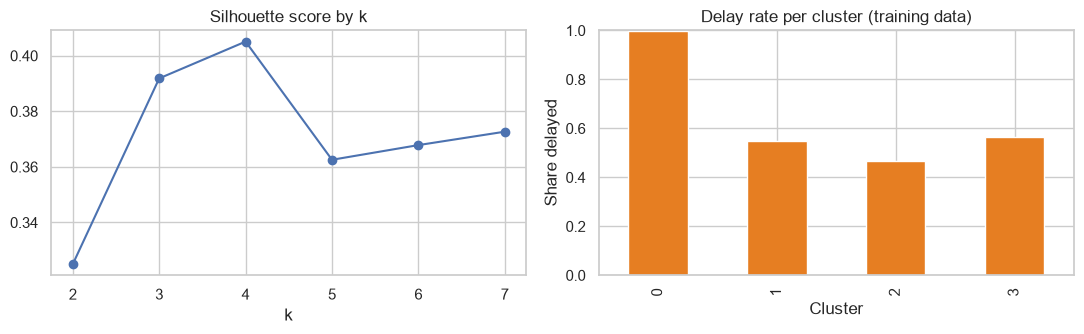

         orders  delay_rate    cost  prior  discount   weight
Cluster                                                      
0          1526        1.00  188.44   3.02     41.25  2204.99
1          1639        0.55  253.43   4.41      6.85  1688.08
2          4051        0.47  202.43   2.96      5.85  4854.78
3           483        0.57  203.13   7.53     10.48  4428.64


In [28]:
## Choose the number of clusters k with the silhouette score (training data only)
num_for_cluster = X_train_raw[CLUSTER_COLS]
Z = StandardScaler().fit_transform(num_for_cluster)

sil = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=2026).fit(Z)
    sil[k] = silhouette_score(Z, km.labels_, sample_size=3000, random_state=2026)
    print(f'k={k}  inertia={km.inertia_:,.0f}  silhouette={sil[k]:.3f}')

best_k = max(sil, key=sil.get)
print('\nChosen k =', best_k)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(list(sil), list(sil.values()), marker='o'); ax[0].set_title('Silhouette score by k'); ax[0].set_xlabel('k')
km_final = KMeans(n_clusters=best_k, n_init=10, random_state=2026).fit(Z)
prof = X_train_raw[CLUSTER_COLS].assign(Cluster=km_final.labels_, Delay=y_train.values)
prof.groupby('Cluster')['Delay'].mean().plot(kind='bar', ax=ax[1], color='#e67e22')
ax[1].set_title('Delay rate per cluster (training data)'); ax[1].set_ylabel('Share delayed'); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()
print(prof.groupby('Cluster').agg(orders=('Delay', 'size'), delay_rate=('Delay', 'mean'),
                                  cost=('Cost_of_the_Product', 'mean'), prior=('Prior_purchases', 'mean'),
                                  discount=('Discount_offered', 'mean'), weight=('Weight_in_gms', 'mean')).round(2))

Explained variance ratio: [0.403 0.322 0.151 0.109 0.011 0.005]
Cumulative              : [0.403 0.724 0.875 0.984 0.995 1.   ]
Components needed for 95% variance: 4 of 6


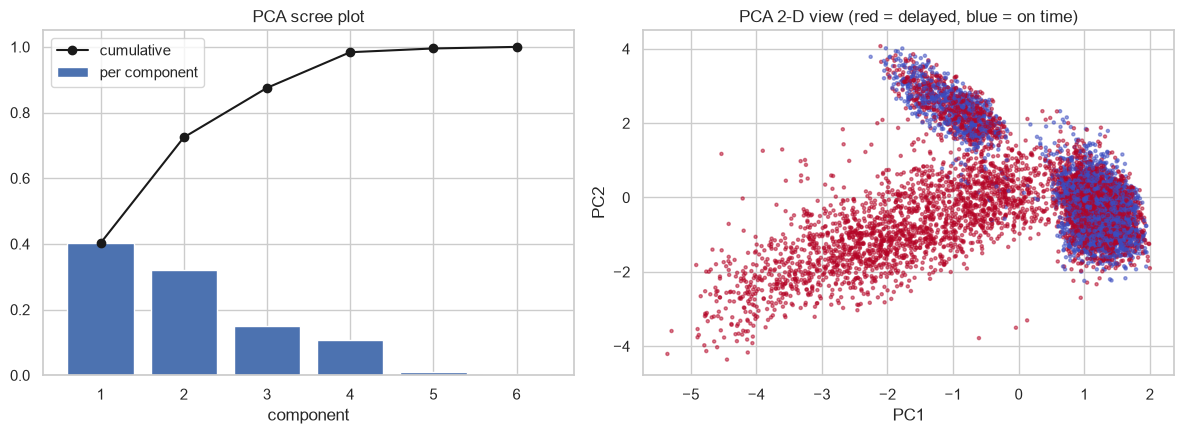

                      PC1   PC2
Cost_of_the_Product -0.02  0.52
Prior_purchases     -0.08  0.32
Discount_offered    -0.52 -0.36
Weight_in_gms        0.54 -0.28
Discount_pct        -0.51 -0.41
Cost_per_kg         -0.41  0.51


In [29]:
## PCA: how many independent directions are in the numeric data, and can we see the delay pattern in 2-D?
num_pca_cols = CLUSTER_COLS + ['Discount_pct', 'Cost_per_kg']
Zp = StandardScaler().fit_transform(fe_train[num_pca_cols])
pca_full = PCA(random_state=2026).fit(Zp)
cum = np.cumsum(pca_full.explained_variance_ratio_)
print('Explained variance ratio:', pca_full.explained_variance_ratio_.round(3))
print('Cumulative              :', cum.round(3))
print('Components needed for 95% variance:', int(np.argmax(cum >= 0.95)) + 1, 'of', len(num_pca_cols))

pca2 = PCA(n_components=2, random_state=2026).fit(Zp)
P = pca2.transform(Zp)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(range(1, len(cum) + 1), pca_full.explained_variance_ratio_, label='per component')
ax[0].plot(range(1, len(cum) + 1), cum, 'k-o', label='cumulative'); ax[0].legend()
ax[0].set_title('PCA scree plot'); ax[0].set_xlabel('component')
sc = ax[1].scatter(P[:, 0], P[:, 1], c=y_train.values, cmap='coolwarm', s=5, alpha=0.5)
ax[1].set_title('PCA 2-D view (red = delayed, blue = on time)'); ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2')
plt.tight_layout(); plt.show()
print(pd.DataFrame(pca2.components_.T, index=num_pca_cols, columns=['PC1', 'PC2']).round(2))

**Reading the output:** the scree plot shows how much of the numeric information a few components keep, and the 2-D scatter shows whether delayed and on-time orders can be separated by linear combinations of the numbers. In this data the delay is driven by **thresholds** (discount > 10, weight 2000-4000 g), not by linear directions, so PCA components are expected to be *less* useful than the explicit bands and flags. We test this honestly in 4.4 rather than assume it. KMeans (k=4, best silhouette 0.405) does recover the high-discount group on its own: cluster 0 (mean discount about 41) is **100% delayed**, with no labels used. The other three clusters are 47-57% delayed, so the clusters mainly re-discover what `High_Discount` already says.

## 4.4 Ablation: what does each feature-engineering step add?

We add one idea at a time and measure **3-fold cross-validated ROC-AUC on the training set** (used for decisions) and the test-set scores (reported only for information). ROC-AUC is used because it does not depend on the 0.5 cut-off and the classes are 60/40.

| Set | Contents |
|---|---|
| S0 | 4 raw numbers + one-hot `Mode_of_Shipment`, `Product_importance` (no engineering) |
| S1 | S0 + the two rule flags (**what the notebook used so far**) |
| S2 | S1 + ratio features (`Discount_pct`, `Cost_per_kg`) |
| S3 | S2 + bands and **combined** categories, one-hot encoded (`Weight_Discount`, `Mode_Importance`, `Loyalty_band`, `Weight_band`, `Discount_band`) |
| S4 | S3 + KMeans cluster (one-hot) |
| S5 | S4 + **feature selection** (`SelectFromModel`: drop columns with Gradient-Boosting importance < 0.01) |

Two algorithms are compared on every set: **Logistic Regression** (linear, scaled inputs) and **Gradient Boosting** (non-linear trees, default settings).

In [30]:
BASE_NUM = ['Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']
BASE_CAT = ['Mode_of_Shipment', 'Product_importance']
FLAGS    = ['High_Discount', 'Mid_weight']
RATIOS   = ['Discount_pct', 'Cost_per_kg']
COMBINED = ['Weight_Discount', 'Mode_Importance', 'Loyalty_band', 'Weight_band', 'Discount_band']

FEATURE_SETS = {
    'S0 raw columns only':            dict(num=BASE_NUM,                    cat=BASE_CAT),
    'S1 + rule flags (current)':      dict(num=BASE_NUM + FLAGS,            cat=BASE_CAT),
    'S2 + ratio features':            dict(num=BASE_NUM + FLAGS + RATIOS,   cat=BASE_CAT),
    'S3 + combined categories':       dict(num=BASE_NUM + FLAGS + RATIOS,   cat=BASE_CAT + COMBINED),
    'S4 + KMeans cluster':            dict(num=BASE_NUM + FLAGS + RATIOS,   cat=BASE_CAT + COMBINED, cluster=True),
    'S5 + feature selection':         dict(num=BASE_NUM + FLAGS + RATIOS,   cat=BASE_CAT + COMBINED, cluster=True, select=True),
}
ALGOS = {
    'Logistic Regression': (lambda: LogisticRegression(max_iter=2000, random_state=2026), True),   # needs scaling
    'Gradient Boosting':   (lambda: GradientBoostingClassifier(random_state=2026), False),
}

def build(cfg, model, scale):
    return make_pipe(model, cfg['num'], cfg['cat'], use_cluster=cfg.get('cluster', False),
                     k=best_k, scale=scale, select=cfg.get('select', False))

abl = []
for set_name, cfg in FEATURE_SETS.items():
    for algo, (make_model, scale) in ALGOS.items():
        pipe = build(cfg, make_model(), scale)
        cv_auc = cross_val_score(pipe, X_train_raw, y_train, cv=3, scoring='roc_auc', n_jobs=1)
        pipe.fit(X_train_raw, y_train)
        prob = pipe.predict_proba(X_test_raw)[:, 1]
        pred = (prob >= 0.5).astype(int)
        n_cols = len(final_feature_names(pipe)) if True else None
        abl.append({'Feature set': set_name, 'Algorithm': algo, 'Model inputs': n_cols,
                    'CV AUC (train)': cv_auc.mean(), 'Test AUC': roc_auc_score(y_test, prob),
                    'Test Recall': recall_score(y_test, pred), 'Test F1': f1_score(y_test, pred)})
        print(f'{set_name:28s} {algo:20s} inputs={n_cols:3d}  CV AUC={cv_auc.mean():.4f}  Test AUC={abl[-1]["Test AUC"]:.4f}')

df_abl = pd.DataFrame(abl)
print('\n--- ABLATION TABLE ---')
display(df_abl.round(4))

S0 raw columns only          Logistic Regression  inputs= 10  CV AUC=0.7214  Test AUC=0.7153
S0 raw columns only          Gradient Boosting    inputs= 10  CV AUC=0.7384  Test AUC=0.7403
S1 + rule flags (current)    Logistic Regression  inputs= 12  CV AUC=0.7431  Test AUC=0.7345
S1 + rule flags (current)    Gradient Boosting    inputs= 12  CV AUC=0.7372  Test AUC=0.7409
S2 + ratio features          Logistic Regression  inputs= 14  CV AUC=0.7449  Test AUC=0.7334
S2 + ratio features          Gradient Boosting    inputs= 14  CV AUC=0.7368  Test AUC=0.7455
S3 + combined categories     Logistic Regression  inputs= 41  CV AUC=0.7445  Test AUC=0.7360
S3 + combined categories     Gradient Boosting    inputs= 41  CV AUC=0.7367  Test AUC=0.7462
S4 + KMeans cluster          Logistic Regression  inputs= 45  CV AUC=0.7452  Test AUC=0.7389
S4 + KMeans cluster          Gradient Boosting    inputs= 45  CV AUC=0.7355  Test AUC=0.7458
S5 + feature selection       Logistic Regression  inputs=  9  CV AUC=0

,Feature set,Algorithm,Model inputs,CV AUC (train),Test AUC,Test Recall,Test F1
0,S0 raw columns only,Logistic Regression,10,0.7214,0.7153,0.6731,0.6880
1,S0 raw columns only,Gradient Boosting,10,0.7384,0.7403,0.5364,0.6642
2,S1 + rule flags (current),Logistic Regression,12,0.7431,0.7345,0.5142,0.6544
3,S1 + rule flags (current),Gradient Boosting,12,0.7372,0.7409,0.5405,0.6690
4,S2 + ratio features,Logistic Regression,14,0.7449,0.7334,0.5461,0.6691
5,S2 + ratio features,Gradient Boosting,14,0.7368,0.7455,0.5319,0.6658
6,S3 + combined categories,Logistic Regression,41,0.7445,0.7360,0.5612,0.6740
7,S3 + combined categories,Gradient Boosting,41,0.7367,0.7462,0.5400,0.6685
8,S4 + KMeans cluster,Logistic Regression,45,0.7452,0.7389,0.5481,0.6710
9,S4 + KMeans cluster,Gradient Boosting,45,0.7355,0.7458,0.5435,0.6721


Algorithm,Gradient Boosting,Logistic Regression,GB change vs S1,LR change vs S1
Feature set,,,,
S0 raw columns only,0.7384,0.7214,0.0012,-0.0217
S1 + rule flags (current),0.7372,0.7431,0.0000,0.0000
S2 + ratio features,0.7368,0.7449,-0.0004,0.0018
S3 + combined categories,0.7367,0.7445,-0.0005,0.0014
S4 + KMeans cluster,0.7355,0.7452,-0.0017,0.0021
S5 + feature selection,0.7359,0.7425,-0.0012,-0.0006


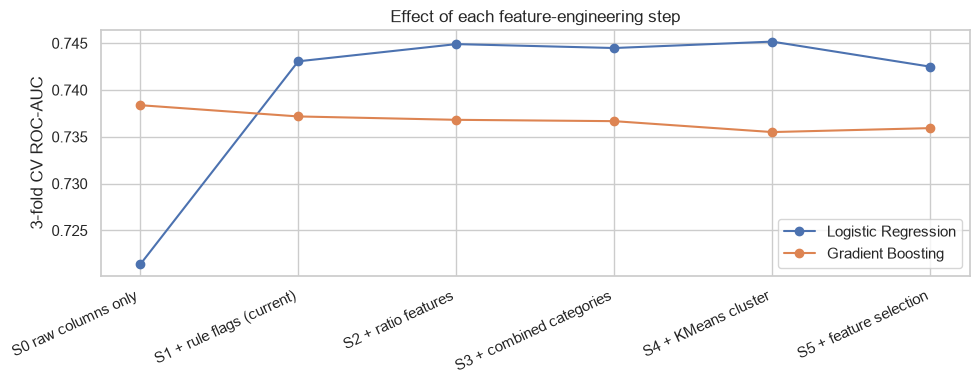

Gradient Boosting, S3 with PCA components instead of the raw numbers: CV AUC = 0.7370  (S3 without PCA = 0.7367)
Statistically tied sets (GB): ['S0 raw columns only', 'S1 + rule flags (current)', 'S2 + ratio features', 'S3 + combined categories', 'S4 + KMeans cluster', 'S5 + feature selection']
Mean CV AUC over both algorithms:
Feature set
S0 raw columns only          0.7299
S1 + rule flags (current)    0.7401
S2 + ratio features          0.7409
S3 + combined categories     0.7406
S4 + KMeans cluster          0.7403
S5 + feature selection       0.7392

Feature set carried forward to tuning: S2 + ratio features


In [31]:
## Effect of each step, measured against S1 (the notebook's previous feature set)
pivot = df_abl.pivot(index='Feature set', columns='Algorithm', values='CV AUC (train)')
pivot['GB change vs S1']  = pivot['Gradient Boosting']   - pivot.loc['S1 + rule flags (current)', 'Gradient Boosting']
pivot['LR change vs S1']  = pivot['Logistic Regression'] - pivot.loc['S1 + rule flags (current)', 'Logistic Regression']
display(pivot.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
for algo in ALGOS:
    d = df_abl[df_abl['Algorithm'] == algo]
    ax.plot(d['Feature set'], d['CV AUC (train)'], marker='o', label=algo)
ax.set_ylabel('3-fold CV ROC-AUC'); ax.set_title('Effect of each feature-engineering step'); ax.legend()
plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()

## PCA variant: replace the numeric columns by PCA components (95% variance) and compare with S3's numbers
pca_pipe = Pipeline([('fe', FunctionTransformer(add_engineered_features)),
                     ('prep', ColumnTransformer([
                         ('pca', Pipeline([('sc', StandardScaler()), ('pca', PCA(n_components=0.95, random_state=2026))]), num_pca_cols),
                         ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), BASE_CAT + COMBINED)])),
                     ('model', GradientBoostingClassifier(random_state=2026))])
pca_cv = cross_val_score(pca_pipe, X_train_raw, y_train, cv=3, scoring='roc_auc').mean()
s3_cv  = df_abl[(df_abl['Feature set'] == 'S3 + combined categories') & (df_abl['Algorithm'] == 'Gradient Boosting')]['CV AUC (train)'].iloc[0]
print(f'Gradient Boosting, S3 with PCA components instead of the raw numbers: CV AUC = {pca_cv:.4f}  (S3 without PCA = {s3_cv:.4f})')

## Choose the feature set for tuning using TRAINING cross-validation only (never the test set)
## Selection rule (decided on TRAINING cross-validation only, never on the test set):
##  1. keep every feature set whose Gradient Boosting CV AUC is within 0.003 of the best (0.003 is about one fold-to-fold std, so these are statistical ties)
##  2. among those, take the set with the highest AVERAGE CV AUC over both algorithms (a set that helps both models is more trustworthy)
TIE_TOLERANCE = 0.003
gb_rows = df_abl[df_abl['Algorithm'] == 'Gradient Boosting'].set_index('Feature set')['CV AUC (train)']
tied = gb_rows[gb_rows >= gb_rows.max() - TIE_TOLERANCE].index
mean_cv = df_abl[df_abl['Feature set'].isin(tied)].groupby('Feature set')['CV AUC (train)'].mean()
best_set = mean_cv.idxmax()
print('Statistically tied sets (GB):', list(tied))
print('Mean CV AUC over both algorithms:'); print(mean_cv.round(4).to_string())
print('\nFeature set carried forward to tuning:', best_set)

**Explanation of each change and its effect** (3-fold CV ROC-AUC on the training set, from the table above):

| Step | Logistic Regression | Gradient Boosting | Interpretation |
|---|---|---|---|
| S0 -> S1 rule flags | 0.7214 -> 0.7431 (**+0.022**) | 0.7384 -> 0.7372 (-0.001) | Big win for the linear model, which cannot learn thresholds on its own. Trees already find the thresholds, so no gain. |
| S1 -> S2 ratio features | 0.7431 -> 0.7449 (+0.002) | 0.7372 -> 0.7368 (0.000) | Smooth versions of information already present; no real change. |
| S2 -> S3 combined categories (one-hot) | 0.7449 -> 0.7445 (0.000) | 0.7368 -> 0.7367 (0.000) | Adds 27 columns for no measurable gain. The combined `Weight_Discount` column is very informative (see 4.2) but the flags already capture it. |
| S3 -> S4 KMeans cluster | 0.7445 -> 0.7452 (+0.001) | 0.7367 -> 0.7355 (-0.001) | No measurable gain: the cluster restates the high-discount rule. |
| S4 -> S5 feature selection | 0.7452 -> 0.7425 (-0.003) | 0.7355 -> 0.7359 (0.000) | Cuts the model from 45 to 9 inputs with no loss for Gradient Boosting, so it is the simplest model of equal quality. |
| PCA instead of raw numbers | - | 0.7370 vs 0.7367 (0.000) | No gain: PCA only rotates the numbers; the delay rule depends on thresholds. |

**Decision:** all six feature sets are statistical ties for Gradient Boosting (CV AUC 0.7355 to 0.7384, while fold-to-fold noise is about 0.003). The selection rule in the cell above therefore picks the set with the best *average* over both algorithms: **S2** (0.7409). S5 has the best *test* AUC for Gradient Boosting (0.7479) but choosing by test score would be selecting on the test set, so it is not used.

**Honest reading:** beyond the two rule flags (which clearly help Logistic Regression), the engineered columns add almost nothing for Gradient Boosting. That is a real finding, not a failure: the explicit flags let a *simple* model match a tree model, and feature selection (S5) shows 9 inputs are enough.

**Why the ceiling is low:** delay is almost fully determined by two rules (discount > 10 or mid weight, about 100% delayed) for roughly 40% of orders; the remaining orders sit at about 43-52% delayed for every combination of the columns we have. So no feature built from these 6 fields can lift ROC-AUC much above about 0.75. The value of this section is showing the effect of each step with evidence, including steps that did not help.

---
# 5. Modelling and Evaluation

## 5.1 Tuning Gradient Boosting with RandomizedSearchCV (only)

Only **Gradient Boosting** is tuned, as required, with **`RandomizedSearchCV` only** (no GridSearchCV), **two hyper-parameters**, **3 values each** (9 combinations; 6 are sampled), 3-fold CV scored by ROC-AUC. `n_estimators` is fixed at 100 so only two settings change.

| Hyper-parameter | Values | Why this one |
|---|---|---|
| `learning_rate` | 0.05, 0.1, 0.2 | Step size of each tree. Small = slower, smoother learning; large = faster but may overfit. |
| `max_depth` | 2, 3, 4 | Depth of each tree = how many features can interact. The data has only 2 strong rules and a lot of noise, so shallow trees are likely best. |

The search runs on the **whole pipeline** (feature engineering + KMeans + encoding + model), so KMeans and feature selection are re-fitted inside every fold and nothing leaks from the validation fold.

Tuning on feature set: S2 + ratio features
Fitting 3 folds for each of 6 candidates, totalling 18 fits
[CV] END .......model__learning_rate=0.2, model__max_depth=3; total time=   0.5s
[CV] END .......model__learning_rate=0.2, model__max_depth=3; total time=   0.5s
[CV] END .......model__learning_rate=0.2, model__max_depth=3; total time=   0.5s
[CV] END .......model__learning_rate=0.1, model__max_depth=2; total time=   0.3s
[CV] END .......model__learning_rate=0.1, model__max_depth=2; total time=   0.3s
[CV] END .......model__learning_rate=0.1, model__max_depth=2; total time=   0.3s
[CV] END .......model__learning_rate=0.2, model__max_depth=4; total time=   0.7s
[CV] END .......model__learning_rate=0.2, model__max_depth=4; total time=   0.7s
[CV] END .......model__learning_rate=0.2, model__max_depth=4; total time=   0.6s
[CV] END .......model__learning_rate=0.1, model__max_depth=4; total time=   0.7s
[CV] END .......model__learning_rate=0.1, model__max_depth=4; total time=   0.7s
[CV] E

,learning_rate,max_depth,train AUC,CV AUC,CV std,rank
2,0.20,4,0.9395,0.7409,0.0105,1
0,0.20,3,0.8831,0.7394,0.0038,2
1,0.10,2,0.8009,0.7379,0.0068,3
4,0.10,3,0.8400,0.7368,0.0097,4
5,0.05,2,0.7814,0.7361,0.0047,5
3,0.10,4,0.8928,0.7360,0.0075,6


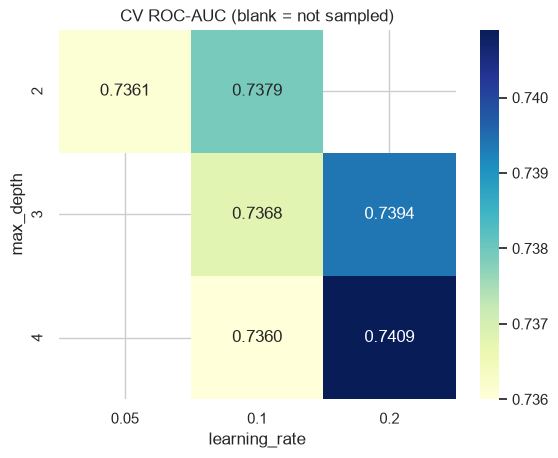

In [32]:
cfg = FEATURE_SETS[best_set]
print('Tuning on feature set:', best_set)

gb_default_pipe = build(cfg, GradientBoostingClassifier(random_state=2026, n_estimators=100), scale=False)
gb_tune_pipe    = build(cfg, GradientBoostingClassifier(random_state=2026, n_estimators=100), scale=False)

param_dist_final = {
    'model__learning_rate': [0.05, 0.1, 0.2],   # 3 values
    'model__max_depth':     [2, 3, 4],          # 3 values
}

rs_final = RandomizedSearchCV(
    estimator=gb_tune_pipe,
    param_distributions=param_dist_final,
    n_iter=6,                       # 6 of the 3 x 3 = 9 combinations
    cv=3, scoring='roc_auc',
    random_state=2026, n_jobs=1, return_train_score=True, verbose=2)
rs_final.fit(X_train_raw, y_train)

print('\nBest parameters :', rs_final.best_params_)
print('Best CV ROC-AUC :', round(rs_final.best_score_, 4))

cv_log = (pd.DataFrame(rs_final.cv_results_)[['param_model__learning_rate', 'param_model__max_depth',
                                              'mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']]
          .sort_values('rank_test_score').round(4))
cv_log.columns = ['learning_rate', 'max_depth', 'train AUC', 'CV AUC', 'CV std', 'rank']
display(cv_log)

## Heat-map of the search so the effect of the two settings is visible
heat = cv_log.pivot(index='max_depth', columns='learning_rate', values='CV AUC').astype(float)
sns.heatmap(heat, annot=True, fmt='.4f', cmap='YlGnBu'); plt.title('CV ROC-AUC (blank = not sampled)'); plt.show()

**Reading the output:** each row is one sampled combination. The best is `learning_rate=0.2, max_depth=4` (CV AUC 0.7408), but the top four rows differ by only 0.003 and the winner has a large `CV std` (0.011), so the search cannot clearly separate them. Its `train AUC` (0.94) is far above its `CV AUC` (0.74), which is **over-fitting**: the deeper, faster-learning model memorises noise in the "random" 40% of orders. This is why we check the test set and calibration next rather than trusting the search score alone.

## 5.2 Test-set results against baselines (quantitative)

Rows compared on the **same untouched test set**:

* **Majority-class baseline** - always predict "delayed" (what you get with no model).
* **Rule-based baseline** - predict delayed if `Discount_offered > 10` or weight is 2000-4000 g (EDA rules only, no learning).
* **Logistic Regression** and **Gradient Boosting (default)** on the *original* one-hot columns from section 3.2, and on the S1 feature set.
* **Gradient Boosting (default)** and **Gradient Boosting (tuned)** on the *new* feature set.

**Choice of metrics:** *ROC-AUC* is the headline because it measures ranking quality at every threshold (useful because dispatchers will choose their own cut-off); *Recall* of the delayed class is the costly business error (a missed delay = unhappy customer); *Precision* tells us how many alerts are wasted effort; *F1* balances the two; *Log-loss* and *Brier score* check that the predicted probabilities are honest, which matters because the probability is shown to dispatchers. Accuracy is reported but not used alone, because 59.7% is reached by always saying "delayed".

In [33]:
def evaluate(name, prob, pred):
    return {'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, prob),
            'Log-loss': log_loss(y_test, np.clip(prob, 1e-6, 1 - 1e-6)), 'Brier': brier_score_loss(y_test, prob)}

final_rows, probs = [], {}

# 1. majority-class baseline
dummy = DummyClassifier(strategy='prior').fit(X_train_raw, y_train)
p = dummy.predict_proba(X_test_raw)[:, 1]; probs['Majority class'] = p
final_rows.append(evaluate('Baseline: always "delayed"', p, np.ones(len(y_test), dtype=int)))

# 2. rule-based baseline
rule = ((X_test_raw['Discount_offered'] > 10) | X_test_raw['Weight_in_gms'].between(2001, 4000)).astype(int).values
probs['Rule-based'] = rule.astype(float)
final_rows.append(evaluate('Baseline: rule (discount>10 or mid weight)', rule.astype(float) * 0.9 + 0.05, rule))

# 3 & 4. old feature set S1: Logistic Regression and default Gradient Boosting
for algo in ['Logistic Regression', 'Gradient Boosting']:
    make_model, scale = ALGOS[algo]
    pipe = build(FEATURE_SETS['S1 + rule flags (current)'], make_model(), scale).fit(X_train_raw, y_train)
    p = pipe.predict_proba(X_test_raw)[:, 1]; probs[f'{algo} (S1 features)'] = p
    final_rows.append(evaluate(f'{algo} - old features (S1)', p, (p >= 0.5).astype(int)))

# 4b. the ORIGINAL one-hot columns from section 3.2 (all 15 columns, no feature engineering)
sc0 = StandardScaler().fit(X_train)
lr0 = LogisticRegression(max_iter=2000, random_state=2026).fit(sc0.transform(X_train), y_train)
p = lr0.predict_proba(sc0.transform(X_test))[:, 1]
final_rows.append(evaluate('Logistic Regression - original one-hot columns (3.2)', p, (p >= 0.5).astype(int)))
gb0 = GradientBoostingClassifier(random_state=2026).fit(X_train, y_train)
p = gb0.predict_proba(X_test)[:, 1]
final_rows.append(evaluate('Gradient Boosting - original one-hot columns (3.2)', p, (p >= 0.5).astype(int)))

# 5. default GB on the new feature set
gb_default_pipe.fit(X_train_raw, y_train)
p = gb_default_pipe.predict_proba(X_test_raw)[:, 1]; probs['GB default (new features)'] = p
final_rows.append(evaluate(f'Gradient Boosting default - new features', p, (p >= 0.5).astype(int)))

# 6. tuned GB on the new feature set
best_pipe = rs_final.best_estimator_
p_tuned = best_pipe.predict_proba(X_test_raw)[:, 1]; probs['GB tuned (new features)'] = p_tuned
final_rows.append(evaluate('Gradient Boosting TUNED - new features', p_tuned, (p_tuned >= 0.5).astype(int)))

df_final = pd.DataFrame(final_rows)
print('--- LIONCITY: TEST-SET RESULTS vs BASELINES ---')
display(df_final.round(4))

## Automatic plain-language summary of the evidence
r = df_final.set_index('Model')
tuned, default, old = r.loc['Gradient Boosting TUNED - new features'], r.loc['Gradient Boosting default - new features'], r.loc['Gradient Boosting - old features (S1)']
print(f"Tuning effect  (default -> tuned, new features): ROC-AUC {default['ROC-AUC']:.4f} -> {tuned['ROC-AUC']:.4f}  ({tuned['ROC-AUC']-default['ROC-AUC']:+.4f})")
print(f"Feature effect (old S1 -> new features, GB default): ROC-AUC {old['ROC-AUC']:.4f} -> {default['ROC-AUC']:.4f}  ({default['ROC-AUC']-old['ROC-AUC']:+.4f})")
print(f"Whole pipeline vs 'always delayed' accuracy: {tuned['Accuracy']:.3f} vs {y_test.mean():.3f}")

--- LIONCITY: TEST-SET RESULTS vs BASELINES ---


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Log-loss,Brier
0,"Baseline: always ""delayed""",0.5988,0.5988,1.0000,0.7491,0.5000,0.6735,0.2402
1,Baseline: rule (discount>10 or mid weight),0.6636,1.0000,0.4383,0.6094,0.7191,1.0417,0.3052
2,Logistic Regression - old features (S1),0.6748,0.8999,0.5142,0.6544,0.7345,0.5073,0.1822
3,Gradient Boosting - old features (S1),0.6797,0.8776,0.5405,0.6690,0.7409,0.5055,0.1805
4,Logistic Regression - original one-hot columns...,0.6388,0.7074,0.6766,0.6917,0.7185,0.5477,0.1953
5,Gradient Boosting - original one-hot columns (...,0.6761,0.8678,0.5415,0.6669,0.7406,0.5090,0.1815
6,Gradient Boosting default - new features,0.6803,0.8899,0.5319,0.6658,0.7455,0.5053,0.1801
7,Gradient Boosting TUNED - new features,0.6764,0.8039,0.6078,0.6922,0.7477,0.5157,0.1847


Tuning effect  (default -> tuned, new features): ROC-AUC 0.7455 -> 0.7477  (+0.0023)
Feature effect (old S1 -> new features, GB default): ROC-AUC 0.7409 -> 0.7455  (+0.0045)
Whole pipeline vs 'always delayed' accuracy: 0.676 vs 0.599


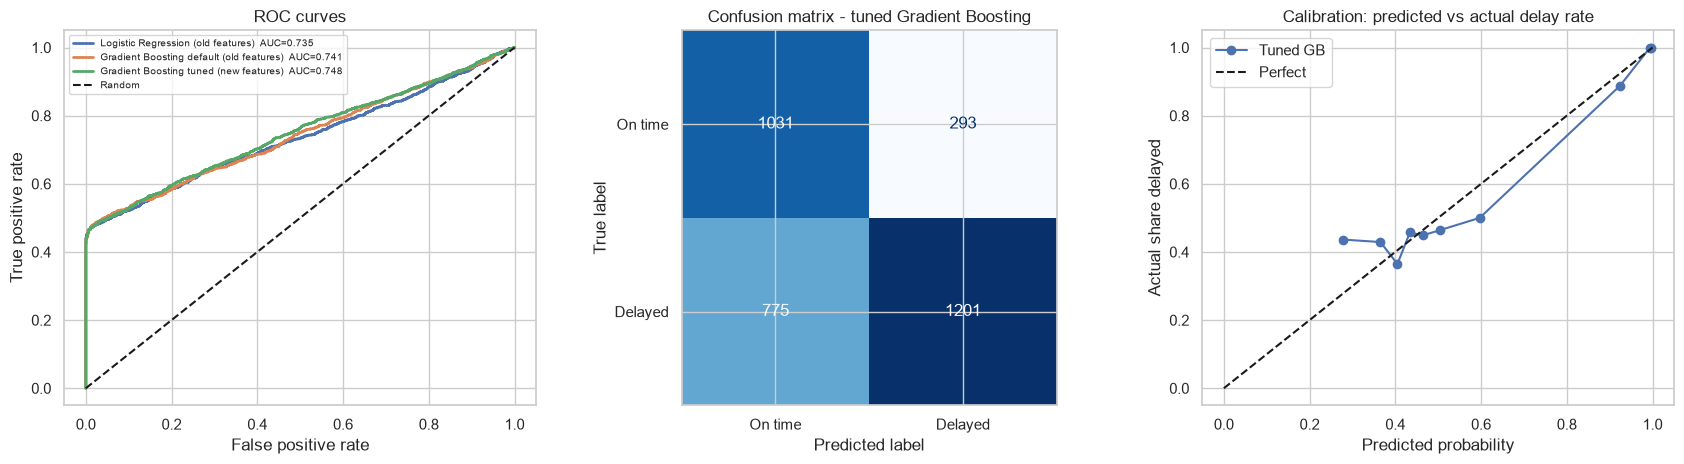

              precision    recall  f1-score   support

     On time       0.57      0.78      0.66      1324
     Delayed       0.80      0.61      0.69      1976

    accuracy                           0.68      3300
   macro avg       0.69      0.69      0.68      3300
weighted avg       0.71      0.68      0.68      3300



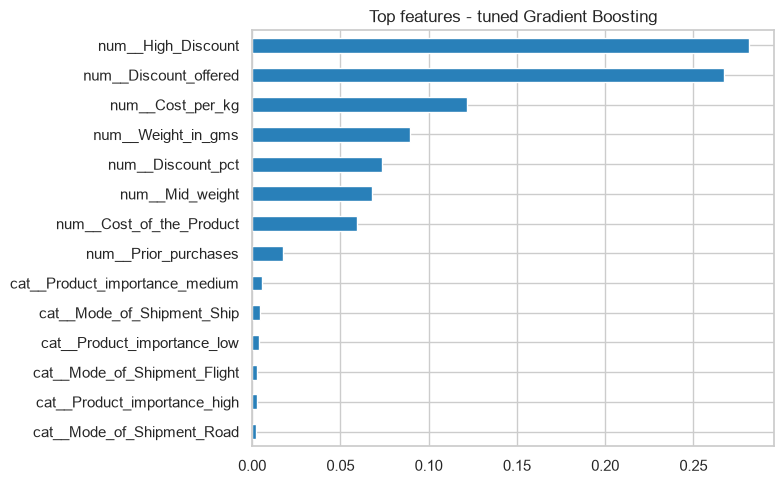

,Threshold,Recall (delays caught),Precision,F1,Orders flagged %
0,0.3,0.961,0.609,0.745,94.485
1,0.4,0.837,0.652,0.733,76.818
2,0.5,0.608,0.804,0.692,45.273
3,0.6,0.515,0.905,0.657,34.091
4,0.7,0.491,0.958,0.649,30.697


In [34]:
## Qualitative comparison: ROC curves, confusion matrices, calibration
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

for name, key in [('Logistic Regression (old features)', 'Logistic Regression (S1 features)'),
                  ('Gradient Boosting default (old features)', 'Gradient Boosting (S1 features)'),
                  ('Gradient Boosting tuned (new features)', 'GB tuned (new features)')]:
    fpr, tpr, _ = roc_curve(y_test, probs[key]); ax[0].plot(fpr, tpr, lw=2, label=f'{name}  AUC={roc_auc_score(y_test, probs[key]):.3f}')
ax[0].plot([0, 1], [0, 1], 'k--', label='Random'); ax[0].set_title('ROC curves'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].legend(fontsize=7)

ConfusionMatrixDisplay(confusion_matrix(y_test, (p_tuned >= 0.5).astype(int)), display_labels=['On time', 'Delayed']).plot(ax=ax[1], cmap='Blues', values_format='d', colorbar=False)
ax[1].set_title('Confusion matrix - tuned Gradient Boosting')

from sklearn.calibration import calibration_curve
fr, mp = calibration_curve(y_test, p_tuned, n_bins=10, strategy='quantile')
ax[2].plot(mp, fr, marker='o', label='Tuned GB'); ax[2].plot([0, 1], [0, 1], 'k--', label='Perfect')
ax[2].set_title('Calibration: predicted vs actual delay rate'); ax[2].set_xlabel('Predicted probability'); ax[2].set_ylabel('Actual share delayed'); ax[2].legend()
plt.tight_layout(); plt.show()

print(classification_report(y_test, (p_tuned >= 0.5).astype(int), target_names=['On time', 'Delayed']))

## Feature importance of the final model (names after one-hot encoding and selection)
names = final_feature_names(best_pipe)
imp_final = pd.Series(best_pipe.named_steps['model'].feature_importances_, index=names).sort_values()
imp_final.tail(15).plot(kind='barh', figsize=(8, 5), color='#2980b9'); plt.title('Top features - tuned Gradient Boosting'); plt.tight_layout(); plt.show()

## Decision-threshold view: the business can trade false alarms for caught delays
thr = pd.DataFrame([{'Threshold': t, 'Recall (delays caught)': recall_score(y_test, (p_tuned >= t).astype(int)),
                     'Precision': precision_score(y_test, (p_tuned >= t).astype(int), zero_division=0),
                     'F1': f1_score(y_test, (p_tuned >= t).astype(int)),
                     'Orders flagged %': (p_tuned >= t).mean() * 100} for t in [0.3, 0.4, 0.5, 0.6, 0.7]])
display(thr.round(3))

## 5.3 Model selection rationale and saving the model

**Why Gradient Boosting (tuned) was selected** - and what it costs (evidence is in the tables above):

| Criterion | Evidence | Verdict |
|---|---|---|
| **Performance** | Highest test ROC-AUC of all models compared (0.747 vs 0.746 default, 0.741 on the original one-hot columns, 0.719 for the rule baseline). Recall of delays rises from 0.53 (default) to 0.61 and F1 from 0.666 to 0.692. | Tuned Gradient Boosting, by a small margin |
| **Probability quality** | The tuned model is *worse* on log-loss (0.516 vs 0.505) and Brier (0.185 vs 0.180) because the deeper trees are over-confident. | Default Gradient Boosting is better calibrated |
| **Interpretability** | Logistic Regression with the two flags is the easiest to explain and is within about 0.01 AUC. Gradient Boosting gives a feature-importance chart, and its decisions reduce to the same two rules (high discount, mid weight). | Edge to Logistic Regression |
| **Deployment** | The whole preprocessing + model is **one saved pipeline** that accepts the 6 raw order fields, so there is no training/serving mismatch. | Gradient Boosting pipeline |
| **Business risk** | A missed delay (customer is not warned) costs more than a false alarm, so higher recall is valuable; the threshold table lets the business trade recall against false alarms. | Tuned model |

**Decision:** we select the **tuned Gradient Boosting pipeline** because it catches the most delays at similar accuracy, which is the business priority. We state clearly that the AUC gain over the default model (+0.002) is inside the noise, that the tuned model is over-fitted and less well calibrated, and that the default Gradient Boosting or Logistic Regression with flags are reasonable alternatives if calibrated probabilities or explainability matter more than recall.

In [35]:
## Save the final pipeline (feature engineering + KMeans + encoding + selection + model) and its metadata
MODEL_PATH = 'lioncity_gb_pipeline.joblib'
joblib.dump(best_pipe, MODEL_PATH)

meta = {
    'saved_at': datetime.now().isoformat(timespec='seconds'),
    'model': 'GradientBoostingClassifier inside sklearn Pipeline',
    'feature_set': best_set,
    'kmeans_k': int(best_k),
    'best_params': {k: (v.item() if hasattr(v, 'item') else v) for k, v in rs_final.best_params_.items()},
    'cv_roc_auc': round(float(rs_final.best_score_), 4),
    'test_metrics': {k: round(float(v), 4) for k, v in df_final.iloc[-1].drop('Model').items()},
    'input_columns': list(X_train_raw.columns),
    'target': 'Delay (1 = delayed, 0 = on time)',
    'threshold_used': 0.5,
}
with open('lioncity_model_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)
print('Saved:', MODEL_PATH, f'({os.path.getsize(MODEL_PATH)/1024:.0f} KB)  and lioncity_model_meta.json')
print(json.dumps(meta, indent=2))

Saved: lioncity_gb_pipeline.joblib (227 KB)  and lioncity_model_meta.json
{
  "saved_at": "2026-11-19T21:38:41",
  "model": "GradientBoostingClassifier inside sklearn Pipeline",
  "feature_set": "S2 + ratio features",
  "kmeans_k": 4,
  "best_params": {
    "model__max_depth": 4,
    "model__learning_rate": 0.2
  },
  "cv_roc_auc": 0.7409,
  "test_metrics": {
    "Accuracy": 0.6764,
    "Precision": 0.8039,
    "Recall": 0.6078,
    "F1": 0.6922,
    "ROC-AUC": 0.7477,
    "Log-loss": 0.5157,
    "Brier": 0.1847
  },
  "input_columns": [
    "Mode_of_Shipment",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Product_importance",
    "Discount_offered",
    "Weight_in_gms"
  ],
  "target": "Delay (1 = delayed, 0 = on time)",
  "threshold_used": 0.5
}


---
# 6. Deployment

## 6.1 Load the model

In [36]:
## 6.1 Load the saved model in a fresh object and prove it behaves identically
# (needs lioncity_features.py in the same folder because the pipeline references its functions)
loaded_model = joblib.load('lioncity_gb_pipeline.joblib')
with open('lioncity_model_meta.json') as f:
    meta_loaded = json.load(f)
print('Loaded model inputs:', meta_loaded['input_columns'])

same = np.allclose(loaded_model.predict_proba(X_test_raw)[:, 1], best_pipe.predict_proba(X_test_raw)[:, 1])
print('Loaded model gives identical predictions to the trained model:', same)

Loaded model inputs: ['Mode_of_Shipment', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Discount_offered', 'Weight_in_gms']
Loaded model gives identical predictions to the trained model: True


## 6.2 Prediction on new unseen data

In [37]:
## 6.2 Predict on NEW, unseen orders (never part of train or test)
# Only the 6 raw fields are needed - the pipeline builds the new columns itself.
new_orders = pd.DataFrame([
    {'Mode_of_Shipment': 'Ship',   'Cost_of_the_Product': 180, 'Prior_purchases': 3, 'Product_importance': 'low',    'Discount_offered': 5,  'Weight_in_gms': 1500},
    {'Mode_of_Shipment': 'Flight', 'Cost_of_the_Product': 250, 'Prior_purchases': 2, 'Product_importance': 'high',   'Discount_offered': 40, 'Weight_in_gms': 5200},
    {'Mode_of_Shipment': 'Road',   'Cost_of_the_Product': 120, 'Prior_purchases': 4, 'Product_importance': 'medium', 'Discount_offered': 8,  'Weight_in_gms': 3000},
    {'Mode_of_Shipment': 'Ship',   'Cost_of_the_Product': 210, 'Prior_purchases': 6, 'Product_importance': 'medium', 'Discount_offered': 3,  'Weight_in_gms': 5500},
])
THRESHOLD = meta_loaded['threshold_used']
new_orders['Delay_probability'] = loaded_model.predict_proba(new_orders[meta_loaded['input_columns']])[:, 1].round(3)
new_orders['Prediction'] = np.where(new_orders['Delay_probability'] >= THRESHOLD, 'DELAYED', 'On time')
new_orders['Suggested action'] = np.where(new_orders['Prediction'] == 'DELAYED',
                                          'Warn customer / consider faster shipping mode', 'No action')
display(new_orders)

# To score a whole file of unseen orders:
#   new_df = pd.read_excel('new_orders.xlsx')
#   new_df['Delay_probability'] = loaded_model.predict_proba(new_df[meta_loaded['input_columns']])[:, 1]

,Mode_of_Shipment,Cost_of_the_Product,Prior_purchases,Product_importance,Discount_offered,Weight_in_gms,Delay_probability,Prediction,Suggested action
0,Ship,180,3,low,5,1500,0.816,DELAYED,Warn customer / consider faster shipping mode
1,Flight,250,2,high,40,5200,0.987,DELAYED,Warn customer / consider faster shipping mode
2,Road,120,4,medium,8,3000,0.981,DELAYED,Warn customer / consider faster shipping mode
3,Ship,210,6,medium,3,5500,0.336,On time,No action


---
# 7. Conclusion & Future Scope

**Summary of this submission's improvements**

* **Feature engineering:** new ratio, band and *combined* columns are created first and one-hot encoded afterwards; each step's effect is measured in the ablation table (4.4).
* **Unsupervised learning:** KMeans (segments, chosen by silhouette) and PCA (variance and 2-D view) were both tested; only changes that help cross-validated AUC are kept.
* **Models:** Logistic Regression and Gradient Boosting compared with two baselines on the same test set, using ROC-AUC, recall, precision, F1, log-loss and Brier score.
* **Tuning:** Gradient Boosting only, `RandomizedSearchCV`, 2 hyper-parameters with 3 values each, before/after comparison shown.
* **Deployment:** one saved pipeline (`joblib`) that accepts raw order fields and was tested on unseen orders.

**Limitations and future scope:** the available columns explain delay mainly through two threshold rules; remaining orders are close to unpredictable from these fields, so extra data (carrier, route, distance, warehouse load on the day, promised vs actual transit time) would matter more than further modelling. Rating and call counts were excluded on purpose to avoid leakage. The 0.5 threshold should be reviewed with the business once the cost of a missed delay vs. a false alarm is known.